# Iris Classification with MyDeZero and PyTorch

Train matching LeNet models on Iris and compare classification results, training throughput, and inference latency on CPU and CUDA. A four-feature logistic regression provides a task baseline. The notebook also compares hyperparameter search methods and explores frozen ResNet50 features.

Iris contains 150 samples with four tabular features. Arrange the standardized sepal length, sepal width, petal length, and petal width in a 2 × 2 grid. Repeat each value in a 16 × 16 block to provide the same 1 × 32 × 32 input to both CNNs. The resulting image encodes the same four values, with an arbitrary spatial arrangement. Use a LeNet-5 variant with ReLU, max pooling, and three outputs. [UCI Iris dataset](https://archive.ics.uci.edu/dataset/53/iris) · [LeNet paper](https://bottou.org/papers/lecun-98h)

Install MyDeZero and the example dependencies from the repository root. The CPU experiment works with CPU-only PyTorch. scikit-learn includes the Iris dataset.

```text
python -m pip install -e .
python -m pip install "scikit-learn==1.6.1" "torch==2.7.1" ipykernel
```

Run the cells in order. Enable CUDA, the TPE search, and frozen ResNet50 using the flags in their respective sections. The saved outputs include runs with all three options enabled.

In [ ]:
import platform
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import sklearn
import torch
from IPython import get_ipython
from IPython.display import Markdown, display
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from threadpoolctl import threadpool_limits
from torch import nn

import mydezero
import mydezero.functions as F
import mydezero.layers as L
import mydezero.optimizers as O

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

SEED = 42
BATCH_SIZE = 15
EPOCHS = 30
TUNING_EPOCHS = 12
N_CLASSES = 3

torch.set_num_threads(1)
cpu_threads = threadpool_limits(limits=1)
iris = load_iris()
features = iris.data.astype(np.float32)
targets = iris.target.astype(np.int64)
class_names = iris.target_names
rng = np.random.default_rng(SEED)
by_class = [rng.permutation(np.flatnonzero(targets == label)) for label in range(N_CLASSES)]
train_ids = rng.permutation(np.concatenate([ids[:30] for ids in by_class]))
val_ids = rng.permutation(np.concatenate([ids[30:40] for ids in by_class]))
test_ids = rng.permutation(np.concatenate([ids[40:] for ids in by_class]))
assert np.unique(np.concatenate((train_ids, val_ids, test_ids))).size == len(features)

mean = features[train_ids].mean(axis=0)
std = features[train_ids].std(axis=0)
standardized = (features - mean) / std


def iris_images(scaled):
    return scaled.reshape(-1, 1, 2, 2).repeat(16, axis=2).repeat(16, axis=3)


images = iris_images(standardized)
splits = [(images[ids], targets[ids]) for ids in (train_ids, val_ids, test_ids)]
train_data, val_data, test_data = splits
rng_batches = np.random.default_rng(SEED + 1)
epoch_orders = [rng_batches.permutation(len(train_ids)) for _ in range(EPOCHS)]

print(f"{platform.system()} / Python {platform.python_version()} / NumPy {np.__version__} / "
      f"scikit-learn {sklearn.__version__} / PyTorch {torch.__version__}")
print("CPU benchmark with one thread per numerical backend.")
for name, (inputs, labels) in zip(("Train", "Validation", "Test"), splits):
    print(f"{name:<10} {inputs.shape}  class counts {np.bincount(labels).tolist()}")

Windows / Python 3.9.25 / NumPy 2.0.2 / scikit-learn 1.6.1 / PyTorch 2.8.0+cu128
CPU benchmark with one thread per numerical backend.
Train      (90, 1, 32, 32)  class counts [30, 30, 30]
Validation (30, 1, 32, 32)  class counts [10, 10, 10]
Test       (30, 1, 32, 32)  class counts [10, 10, 10]


## Dataset Split and Benchmark Controls

Use seed 42 and stratify the data by class. Each class contributes 30 training, 10 validation, and 10 test examples, for totals of 90, 30, and 30. Fit feature standardization on the training split and reuse those statistics for validation and test features. [scikit-learn guidance on data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

The two LeNet implementations share the architecture, initial weights, batch order, mean cross-entropy loss, optimizer settings, and epoch count. Transpose the linear weights to match each framework's layout. Compare SGD, momentum SGD, and Adam on MyDeZero's validation run, ranking by macro F1 and then by lower validation loss. Apply the selected configuration to both frameworks. Check initial logits, the first batch's loss and gradients, and the first optimizer update before measuring performance.

Use the validation split to select checkpoints. Define convergence as the first epoch in a streak of three validation accuracies at or above 90%. Score the selected checkpoints on the fixed test split and treat the previously inspected split as exploratory.

The logistic baseline uses the four standardized features, training labels, and a fixed `C=1.0`. Evaluating it on the same test split gives a reference for classification using the original features.

In [ ]:
class MyDeZeroLeNet(mydezero.Model):
    def __init__(self):
        super().__init__()
        self.conv1 = L.Conv2d(6, 5, in_channels=1)
        self.conv2 = L.Conv2d(16, 5, in_channels=6)
        self.fc1 = L.Linear(120, in_size=400)
        self.fc2 = L.Linear(84, in_size=120)
        self.fc3 = L.Linear(N_CLASSES, in_size=84)

    def forward(self, x):
        x = F.pooling(F.relu(self.conv1(x)), 2, stride=2)
        x = F.pooling(F.relu(self.conv2(x)), 2, stride=2)
        x = x.reshape(x.shape[0], 400)
        return self.fc3(F.relu(self.fc2(F.relu(self.fc1(x)))))


class TorchLeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(400, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, N_CLASSES)

    def forward(self, x):
        x = nn.functional.max_pool2d(self.conv1(x).relu(), 2)
        x = nn.functional.max_pool2d(self.conv2(x).relu(), 2)
        x = x.flatten(1)
        return self.fc3(self.fc2(self.fc1(x).relu()).relu())


layer_names = ("conv1", "conv2", "fc1", "fc2", "fc3")
weight_shapes = ((6, 1, 5, 5), (16, 6, 5, 5), (400, 120), (120, 84), (84, N_CLASSES))
fan_ins = (25, 150, 400, 120, 84)
rng_weights = np.random.default_rng(SEED + 2)
initial = {
    name: (rng_weights.standard_normal(shape).astype(np.float32) * np.float32(np.sqrt(2 / fan_in)),
           np.zeros(shape[0] if name.startswith("conv") else shape[1], dtype=np.float32))
    for name, shape, fan_in in zip(layer_names, weight_shapes, fan_ins)
}


def to_host(array):
    if torch.is_tensor(array):
        return array.detach().cpu().numpy()
    return mydezero.cuda.as_numpy(array)


class MyDeZeroTrial:
    def __init__(self, model, names, initial_arrays, config, xp=np):
        self.model = model
        self.layers = [getattr(model, name) for name in names]
        self.xp = xp
        if xp is not np:
            self.model.to_gpu()
        self.restore([initial_arrays[name] for name in names])
        kind, lr = config
        self.optimizer = {"SGD": O.SGD, "Momentum": O.MomentumSGD, "Adam": O.Adam}[kind](lr=lr)
        self.optimizer.setup(model)

    def arrays(self, grad=False):
        if grad:
            return [(layer.W.grad.data, layer.b.grad.data) for layer in self.layers]
        return [(layer.W.data, layer.b.data) for layer in self.layers]

    def restore(self, arrays):
        for (weight, bias), (source_w, source_b) in zip(self.arrays(), arrays):
            weight[...] = self.xp.asarray(source_w)
            bias[...] = self.xp.asarray(source_b)

    def backward(self, x, y):
        self.model.cleargrads()
        loss = F.softmax_cross_entropy(self.model(x), y)
        loss.backward()
        return loss.data

    def update(self):
        self.optimizer.update()

    def predict(self, x):
        with mydezero.test_mode(), mydezero.no_grad():
            return self.model(x).data

    def synchronize(self):
        if self.xp is not np:
            self.xp.cuda.runtime.deviceSynchronize()


class TorchTrial:
    def __init__(self, config, device="cpu"):
        self.device = torch.device(device)
        self.model = TorchLeNet().to(self.device)
        self.layers = [getattr(self.model, name) for name in layer_names]
        self.restore([initial[name] for name in layer_names])
        kind, lr = config
        if kind == "Adam":
            self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr, foreach=False)
        else:
            self.optimizer = torch.optim.SGD(self.model.parameters(), lr=lr,
                                             momentum=0.9 if kind == "Momentum" else 0,
                                             foreach=False)

    def arrays(self, grad=False):
        arrays = []
        for layer in self.layers:
            weight = layer.weight.grad if grad else layer.weight.detach()
            bias = layer.bias.grad if grad else layer.bias.detach()
            arrays.append((weight.T if weight.ndim == 2 else weight, bias))
        return arrays

    def restore(self, arrays):
        for (weight, bias), (source_w, source_b) in zip(self.arrays(), arrays):
            weight.copy_(torch.as_tensor(source_w, device=self.device))
            bias.copy_(torch.as_tensor(source_b, device=self.device))

    def backward(self, x, y):
        self.optimizer.zero_grad(set_to_none=True)
        logits = self.model(torch.as_tensor(x, device=self.device))
        loss = nn.functional.cross_entropy(logits, torch.as_tensor(y, device=self.device))
        loss.backward()
        return loss.detach()

    def update(self):
        self.optimizer.step()

    def predict(self, x):
        with torch.inference_mode():
            return self.model(torch.as_tensor(x, device=self.device))

    def synchronize(self):
        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)


def my_lenet(config, xp=np):
    return MyDeZeroTrial(MyDeZeroLeNet(), layer_names, initial, config, xp=xp)


def verify_training_step(left, right, left_batch, right_batch):
    np.testing.assert_allclose(to_host(left.predict(left_batch[0])),
                               to_host(right.predict(right_batch[0])), rtol=1e-4, atol=1e-5)
    np.testing.assert_allclose(to_host(left.backward(*left_batch)),
                               to_host(right.backward(*right_batch)), rtol=1e-5, atol=1e-6)
    for a, b in zip(left.arrays(grad=True), right.arrays(grad=True)):
        for left_grad, right_grad in zip(a, b):
            np.testing.assert_allclose(to_host(left_grad), to_host(right_grad), rtol=1e-4, atol=1e-5)
    left.update()
    right.update()
    for a, b in zip(left.arrays(), right.arrays()):
        for left_param, right_param in zip(a, b):
            np.testing.assert_allclose(to_host(left_param), to_host(right_param), rtol=1e-4, atol=1e-5)


params = sum(weight.size + bias.size for weight, bias in initial.values())
macs = 6 * 28**2 * 25 + 16 * 10**2 * 150 + 400 * 120 + 120 * 84 + 84 * N_CLASSES
print(f"Both LeNet implementations have {params:,} parameters and about {macs:,} MACs per sample"
      f" ({2 * macs:,} FLOPs for convolution and linear layers).")

Both LeNet implementations have 61,111 parameters and about 415,932 MACs per sample (831,864 FLOPs for convolution and linear layers).


## Metrics and Timing

Report accuracy, macro precision, macro recall, and macro F1. Macro averages give each class equal weight. Assign precision zero when the model predicts no samples for a class. With 10 test samples per class, macro recall equals accuracy. Confusion matrices show true classes in rows and predicted classes in columns.

Training time sums gradient clearing, the forward and backward passes, and parameter updates. Batch selection, validation, gradient diagnostics, and metric calculation are measured outside that total. Compute throughput as the total training samples processed divided by the measured training time. For inference, warm up and report the median of 31 calls at batch sizes 1 and 15. The theoretical MAC and FLOP estimates cover convolution and linear layers in the shared model.

In [ ]:
def classification_scores(labels, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predicted, labels=np.arange(N_CLASSES), average="macro", zero_division=0)
    return np.array([np.mean(labels == predicted), precision, recall, f1])


def evaluate(trial, data):
    x, labels = data
    logits = to_host(trial.predict(x))
    labels = to_host(labels)
    shifted = logits - logits.max(axis=1, keepdims=True)
    loss = np.mean(np.log(np.exp(shifted).sum(axis=1)) - shifted[np.arange(len(labels)), labels])
    return float(loss), classification_scores(labels, logits.argmax(axis=1))


def fit(trial, train, validation, epochs, *, batch_orders=epoch_orders):
    x, y = train
    history = []
    best = None
    failure = None
    timed_seconds = 0.0
    samples = 0
    for epoch, order in enumerate(batch_orders[:epochs], start=1):
        step_norms = []
        for start in range(0, len(order), BATCH_SIZE):
            batch_ids = order[start:start + BATCH_SIZE]
            batch_x, batch_y = x[batch_ids], y[batch_ids]
            trial.synchronize()
            started = perf_counter()
            loss = trial.backward(batch_x, batch_y)
            trial.synchronize()
            timed_seconds += perf_counter() - started
            norms = np.array([np.linalg.norm(to_host(w).astype(np.float64)) for w, _ in trial.arrays(grad=True)])
            if not np.isfinite(to_host(loss)) or not np.isfinite(norms).all():
                failure = (epoch, start // BATCH_SIZE + 1)
                break
            step_norms.append(norms)
            started = perf_counter()
            trial.update()
            trial.synchronize()
            timed_seconds += perf_counter() - started
            samples += len(batch_ids)
        if failure is not None:
            break

        train_loss, train_scores = evaluate(trial, train)
        val_loss, val_scores = evaluate(trial, validation)
        if not np.isfinite([train_loss, val_loss]).all():
            failure = (epoch, "evaluation")
            break
        row = dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                   train_accuracy=train_scores[0], val_accuracy=val_scores[0], val_f1=val_scores[3],
                   grad_first=np.median(step_norms, axis=0)[0],
                   grad_last=np.median(step_norms, axis=0)[-1],
                   grad_peak=np.max(step_norms))
        history.append(row)
        key = (row["val_f1"], -row["val_loss"])
        if best is None or key > best["key"]:
            arrays = [(to_host(w).copy(), to_host(b).copy()) for w, b in trial.arrays()]
            best = dict(row=row, key=key, arrays=arrays)

    if best is not None:
        trial.restore(best["arrays"])
    return dict(trial=trial, history=history, best=best,
                seconds=timed_seconds, samples=samples, failure=failure)


def convergence_epoch(history, threshold=0.9, streak=3):
    accuracies = [row["val_accuracy"] for row in history]
    return next((i + 1 for i in range(len(accuracies) - streak + 1)
                 if min(accuracies[i:i + streak]) >= threshold), None)


def inference_ms(trial, input_batch):
    for _ in range(5):
        trial.predict(input_batch)
    trial.synchronize()
    samples = []
    for _ in range(31):
        started = perf_counter()
        trial.predict(input_batch)
        trial.synchronize()
        samples.append((perf_counter() - started) * 1e3)
    return np.median(samples)

## Single-Thread CPU Benchmark

Use the same 30-epoch training schedule for MyDeZero and PyTorch, with one thread per numerical backend. The table reports both classification scores and runtime metrics for the same LeNet configuration.

In [ ]:
candidates = [("SGD", 0.02), ("Momentum", 0.02), ("Adam", 0.001), ("Adam", 0.003)]
tuning = {}
print("Optimizer / rate     Best validation macro F1 / loss")
for config in candidates:
    run = fit(my_lenet(config), train_data, val_data, TUNING_EPOCHS)
    tuning[config] = run["best"]
    if run["best"] is not None:
        row = run["best"]["row"]
        print(f"{config[0]:<10} {config[1]:.3f}   {row['val_f1']:.4f} / {row['val_loss']:.4f}")

selected = max((config for config in candidates if tuning[config] is not None),
               key=lambda config: tuning[config]["key"])
print("Configuration selected on validation data", selected, "(SGD momentum: 0.9)")

batch = tuple(a[:BATCH_SIZE] for a in train_data)
verify_training_step(my_lenet(selected), TorchTrial(selected), batch, batch)
print("CPU agreement checked for initial logits, first loss, gradients, and parameter update.")

runs = {
    "MyDeZero": fit(my_lenet(selected), train_data, val_data, EPOCHS),
    "PyTorch": fit(TorchTrial(selected), train_data, val_data, EPOCHS),
}
assert all(run["failure"] is None for run in runs.values())

Optimizer / rate     Best validation macro F1 / loss
SGD        0.020   1.0000 / 0.0798
Momentum   0.020   1.0000 / 0.1397
Adam       0.001   1.0000 / 0.0428
Adam       0.003   1.0000 / 0.0387
Configuration selected on validation data ('Adam', 0.003) (SGD momentum: 0.9)
CPU agreement checked for initial logits, first loss, gradients, and parameter update.


| CPU metric | MyDeZero | PyTorch |
| --- | ---: | ---: |
| Correct predictions | 29/30 | 29/30 |
| Accuracy | 0.9667 | 0.9667 |
| Macro precision | 0.9697 | 0.9697 |
| Macro recall | 0.9667 | 0.9667 |
| Macro F1 | 0.9666 | 0.9666 |
| Selected checkpoint epoch | 28 | 19 |
| Convergence epoch | 2 | 2 |
| Training time (s) | 2.871 | 0.769 |
| Training throughput (samples/s) | 940 | 3,511 |
| Median inference, batch 1 (ms) | 0.5753 | 0.1429 |
| Median inference, batch 15 (ms) | 6.6496 | 0.6460 |

Both LeNet models agreed on 30/30 test predictions.
Four-feature logistic regression answered 30/30 correctly. Accuracy=1.0000, Macro precision=1.0000, Macro recall=1.0000, Macro F1=1.0000


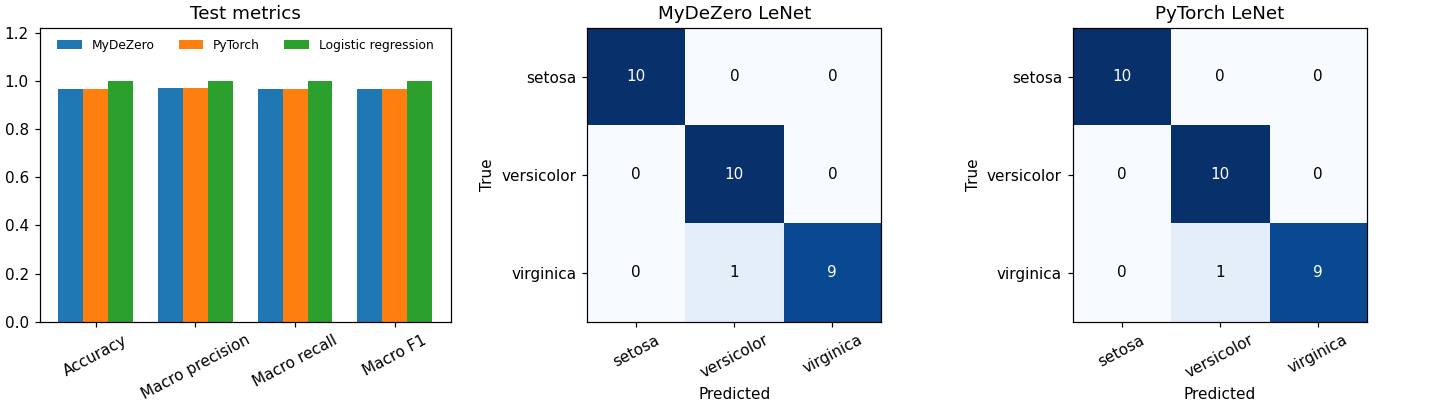

In [ ]:
metric_names = ("Accuracy", "Macro precision", "Macro recall", "Macro F1")
test_scores = {}
test_predictions = {}
cpu_measurements = {}
for name, run in runs.items():
    predicted = to_host(run["trial"].predict(test_data[0])).argmax(axis=1)
    scores = classification_scores(test_data[1], predicted)
    test_predictions[name] = predicted
    test_scores[name] = scores
    correct = np.count_nonzero(predicted == test_data[1])
    latency = [inference_ms(run["trial"], test_data[0][:size]) for size in (1, BATCH_SIZE)]
    cpu_measurements[name] = (
        f"{correct}/{len(predicted)}", *(f"{score:.4f}" for score in scores),
        str(run["best"]["row"]["epoch"]), str(convergence_epoch(run["history"]) or "Not reached"),
        f"{run['seconds']:.3f}", f"{run['samples'] / run['seconds']:,.0f}",
        *(f"{value:.4f}" for value in latency),
    )

metrics = (
    "Correct predictions", *metric_names, "Selected checkpoint epoch", "Convergence epoch",
    "Training time (s)", "Training throughput (samples/s)", "Median inference, batch 1 (ms)",
    f"Median inference, batch {BATCH_SIZE} (ms)",
)
table = ["| CPU metric | MyDeZero | PyTorch |", "| --- | ---: | ---: |"]
for metric, left, right in zip(metrics, cpu_measurements["MyDeZero"], cpu_measurements["PyTorch"]):
    table.append(f"| {metric} | {left} | {right} |")
display(Markdown("\n".join(table)))

agreement = np.count_nonzero(test_predictions["MyDeZero"] == test_predictions["PyTorch"])
print(f"Both LeNet models agreed on {agreement}/{len(test_ids)} test predictions.")

tabular = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)
tabular.fit(standardized[train_ids], targets[train_ids])
tabular_predictions = tabular.predict(standardized[test_ids])
tabular_scores = classification_scores(targets[test_ids], tabular_predictions)
tabular_correct = np.count_nonzero(tabular_predictions == targets[test_ids])
print(f"Four-feature logistic regression answered {tabular_correct}/{len(test_ids)} correctly. "
      + ", ".join(f"{k}={v:.4f}" for k, v in zip(metric_names, tabular_scores)))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), layout="constrained")
offsets = np.arange(len(metric_names))
for i, (name, scores) in enumerate(test_scores.items()):
    axes[0].bar(offsets + (i - 1) * 0.25, scores, width=0.25, label=name)
axes[0].bar(offsets + 0.25, tabular_scores, width=0.25,
            label="Logistic regression")

for ax, (name, predicted) in zip(axes[1:], test_predictions.items()):
    matrix = confusion_matrix(test_data[1], predicted, labels=np.arange(N_CLASSES))
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=10)
    for row, col in np.ndindex(matrix.shape):
        ax.text(col, row, str(matrix[row, col]), ha="center", va="center",
                color="white" if matrix[row, col] > 5 else "black")
    ax.set(xticks=range(N_CLASSES), yticks=range(N_CLASSES),
           xticklabels=class_names, yticklabels=class_names,
           xlabel="Predicted", ylabel="True",
           title=f"{name} LeNet")
    ax.tick_params(axis="x", labelrotation=28)
axes[0].set(xticks=offsets, xticklabels=metric_names, ylim=(0, 1.22),
            title="Test metrics")
axes[0].tick_params(axis="x", labelrotation=28)
axes[0].legend(loc="upper center", ncol=3, fontsize=8, frameon=False)
plt.show()

## MyDeZero Training Diagnostics

The top plots show training and validation cross-entropy and accuracy. Vertical lines mark the checkpoint selected on validation data. A sustained increase in validation loss and a widening training–validation gap can indicate overfitting.

The lower-left plot shows median batch gradient norms for the first convolution and final linear layer, with the peak over all measured weight gradients. Layer size and parameter scale affect these norms, so read them together with loss and accuracy.

The stress test uses the same initial weights and batch order for the first 12 epochs, with a learning rate of 1.0. Count an increase in validation loss when consecutive epochs differ by more than 0.02 in the upward direction. The stress test is diagnostic. On the logarithmic plots, zero values are displayed at `1e-12`.

Selected configuration, full run: train/validation accuracy 0.911/0.900, train/validation loss 0.229/0.189. validation loss increases 6/29. peak validation loss 0.625. peak gradient norm 17.24. non-finite stop none
Selected configuration, first 12 epochs: train/validation accuracy 0.967/1.000, train/validation loss 0.144/0.048. validation loss increases 2/11. peak validation loss 0.625. peak gradient norm 17.24. non-finite stop none
Stress test, learning rate 1.0: train/validation accuracy 0.333/0.333, train/validation loss 1.101/1.101. validation loss increases 3/11. peak validation loss 2.396e+05. peak gradient norm 4.522e+06. non-finite stop none
First-to-final layer gradient norm ratio: first epoch 0.31, last epoch 2.99


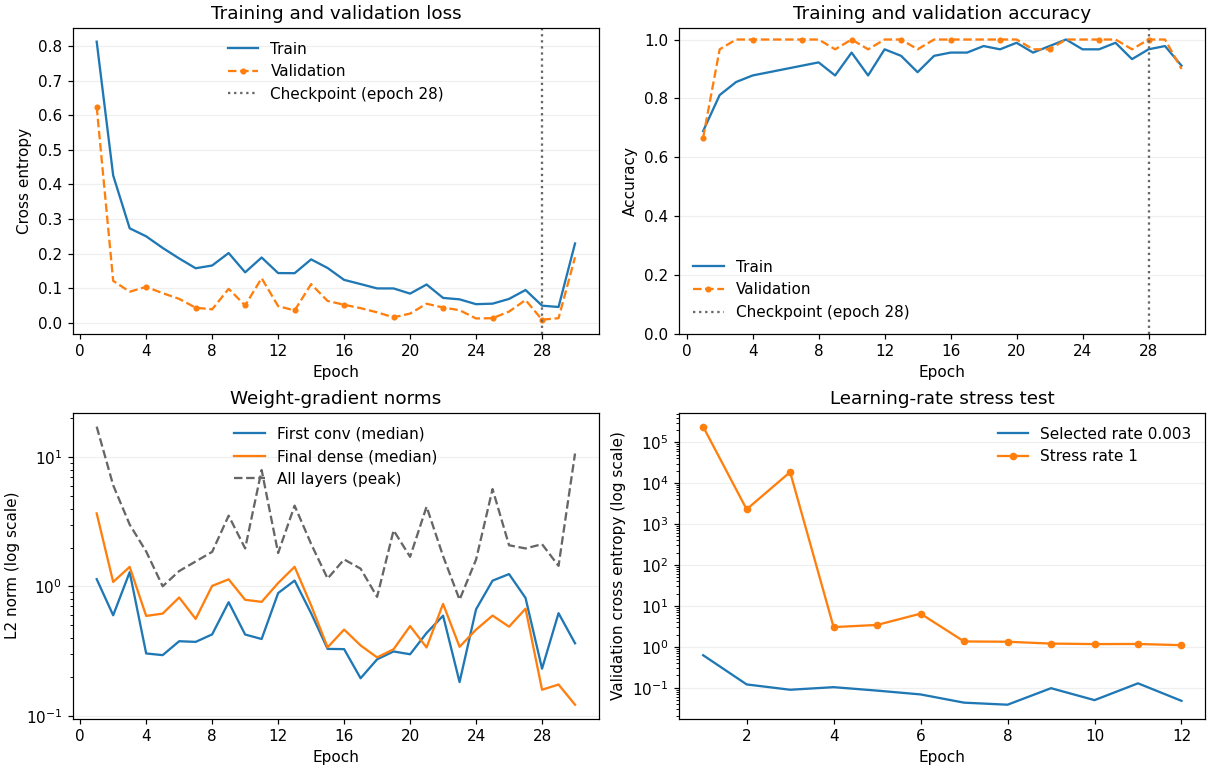

In [ ]:
baseline = runs["MyDeZero"]["history"]
stress_epochs = 12
stress_config = selected[0], 1.0
with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    stress = fit(my_lenet(stress_config), train_data, val_data, stress_epochs)


def series(history, key):
    return [row[key] for row in history]


def show_training_summary(name, history, failure):
    if not history:
        print(f"{name}: No completed epochs. Stop: {failure}")
        return
    last = history[-1]
    rises = np.count_nonzero(np.diff(series(history, "val_loss")) > 0.02)
    print(f"{name}: train/validation accuracy {last['train_accuracy']:.3f}/{last['val_accuracy']:.3f}, "
          f"train/validation loss {last['train_loss']:.3f}/{last['val_loss']:.3f}. "
          f"validation loss increases {rises}/{len(history) - 1}. peak validation loss "
          f"{max(series(history, 'val_loss')):.4g}. peak gradient norm "
          f"{max(series(history, 'grad_peak')):.4g}. non-finite stop {failure or 'none'}")


show_training_summary("Selected configuration, full run", baseline, None)
show_training_summary("Selected configuration, first 12 epochs", baseline[:stress_epochs], None)
show_training_summary(f"Stress test, learning rate {stress_config[1]}", stress["history"], stress["failure"])
early = np.array(series(baseline, "grad_first"))
late = np.array(series(baseline, "grad_last"))
print(f"First-to-final layer gradient norm ratio: "
      f"first epoch {early[0] / max(late[0], 1e-12):.3g}, "
      f"last epoch {early[-1] / max(late[-1], 1e-12):.3g}")

epochs = series(baseline, "epoch")
checkpoint = runs["MyDeZero"]["best"]["row"]["epoch"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
loss_ax, accuracy_ax, gradient_ax, stress_ax = axes.flat

for ax, metric in ((loss_ax, "loss"), (accuracy_ax, "accuracy")):
    ax.plot(epochs, series(baseline, f"train_{metric}"), color="tab:blue", label="Train")
    ax.plot(epochs, series(baseline, f"val_{metric}"), color="tab:orange",
            linestyle="--", marker="o", markersize=3, markevery=3, label="Validation")
    ax.axvline(checkpoint, color="0.4", linestyle=":", label=f"Checkpoint (epoch {checkpoint})")
loss_ax.set(title="Training and validation loss",
            ylabel="Cross entropy")
accuracy_ax.set(title="Training and validation accuracy",
                ylabel="Accuracy", ylim=(0, 1.04))


def positive(values):
    return np.maximum(values, 1e-12)


gradient_ax.semilogy(epochs, positive(early), label="First conv (median)")
gradient_ax.semilogy(epochs, positive(late), label="Final dense (median)")
gradient_ax.semilogy(epochs, positive(series(baseline, "grad_peak")), color="0.4",
                     linestyle="--", label="All layers (peak)")
gradient_ax.set(title="Weight-gradient norms",
                ylabel="L2 norm (log scale)")

matched = baseline[:stress_epochs]
stress_ax.semilogy(series(matched, "epoch"), positive(series(matched, "val_loss")),
                   label=f"Selected rate {selected[1]:g}")
stress_ax.semilogy(series(stress["history"], "epoch"), positive(series(stress["history"], "val_loss")),
                   marker="o", markersize=4, label=f"Stress rate {stress_config[1]:g}")
if stress["failure"] is not None:
    stress_ax.axvline(stress["failure"][0], color="tab:red", linestyle=":", label="Non-finite stop")
stress_ax.set(title="Learning-rate stress test",
              ylabel="Validation cross entropy (log scale)")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)
plt.show()

## Hyperparameter Search

The four original candidates tied on their best validation macro F1. To explore training stability and probability estimates, rank optimizers and learning rates by **mean validation cross-entropy over three folds at epoch 12**. Also report macro F1 and trials stopped by non-finite values. Every trial has the same epoch limit and counts against the budget even if it stops early.

- **Manual candidates** re-evaluate the original four settings on the same folds.
- **Grid search** tries four learning rates per optimizer to show how both choices affect training.
- **Random search** draws four log-uniform learning rates per optimizer over the same ranges. Each of the three seeds has the same 12-trial budget as the grid. [Random search paper](https://www.jmlr.org/papers/v13/bergstra12a.html)
- **Optional Bayesian search** uses Optuna's TPE to select candidates from previous trial results. The 12 trials per seed include four random startup trials. Install Optuna in the notebook environment and set `RUN_TPE_SEARCH = True` to run it. [Optuna TPE documentation](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)

Search on the 90 training examples. In each fold, fit standardization and train on 60 examples, then score on the other 30. All candidates share the folds, initial weights, and batch order within each fold. Any non-finite fold disqualifies its candidate. For each search run, refit its selected configuration for 12 epochs on all 90 training examples and score on the original 30-example validation split. The original test split is reserved for the model comparisons.

The left plot shows the grid trials that completed. The right plot shows the best loss found after each trial. The grid uses a fixed order. Shaded ranges span the three seeds of each stochastic method. The search wall time includes fold evaluation and diagnostics. The saved output includes TPE.

In [ ]:
from sklearn.model_selection import StratifiedKFold

RUN_TPE_SEARCH = False
if RUN_TPE_SEARCH:
    import optuna

SEARCH_SEEDS = (42, 43, 44)
grid_rates = {
    "SGD": (0.002, 0.02, 0.2, 1.0),
    "Momentum": (0.002, 0.02, 0.2, 1.0),
    "Adam": (0.0003, 0.003, 0.03, 0.3),
}
grid_configs = [(kind, lr) for kind, rates in grid_rates.items() for lr in rates]
budget = len(grid_configs)


def stratified_search_folds():
    splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    for fold, (fit_rows, score_rows) in enumerate(splitter.split(features[train_ids], targets[train_ids])):
        fit_ids, score_ids = train_ids[fit_rows], train_ids[score_rows]
        center = features[fit_ids].mean(axis=0)
        scale = features[fit_ids].std(axis=0)
        datasets = []
        for ids in (fit_ids, score_ids):
            scaled = (features[ids] - center) / scale
            datasets.append((iris_images(scaled), targets[ids]))
        order_rng = np.random.default_rng(SEED + fold)
        orders = [order_rng.permutation(len(fit_ids)) for _ in range(TUNING_EPOCHS)]
        yield datasets[0], datasets[1], orders


search_folds = list(stratified_search_folds())


def score_config(config):
    final_rows = []
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        for train, validation, orders in search_folds:
            run = fit(my_lenet(config), train, validation, TUNING_EPOCHS, batch_orders=orders)
            if run["failure"] is None:
                final_rows.append(run["history"][-1])
    failures = len(search_folds) - len(final_rows)
    loss = np.inf if failures else float(np.mean([row["val_loss"] for row in final_rows]))
    f1 = np.nan if failures else float(np.mean([row["val_f1"] for row in final_rows]))
    return dict(config=config, loss=loss, f1=f1, failures=failures)


def run_search(configs):
    started = perf_counter()
    rows = [score_config(config) for config in configs]
    return rows, perf_counter() - started


def random_configs(seed):
    rng = np.random.default_rng(seed)
    configs = [(kind, float(np.exp(value)))
               for kind, rates in grid_rates.items()
               for value in rng.uniform(np.log(rates[0]), np.log(rates[-1]), size=len(rates))]
    return [configs[i] for i in rng.permutation(len(configs))]


grid_order = np.random.default_rng(SEED).permutation(budget)
search_runs = {
    "manual": [run_search(candidates)],
    "grid": [run_search(grid_configs[i] for i in grid_order)],
    "random": [run_search(random_configs(seed)) for seed in SEARCH_SEEDS],
}

if RUN_TPE_SEARCH:
    def run_tpe(seed):
        rows = []

        def objective(trial):
            kind = trial.suggest_categorical("optimizer", list(grid_rates))
            rates = grid_rates[kind]
            lr = trial.suggest_float(f"{kind}_lr", rates[0], rates[-1], log=True)
            row = score_config((kind, lr))
            rows.append(row)
            return row["loss"]

        started = perf_counter()
        study = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=4))
        study.optimize(objective, n_trials=budget)
        return rows, perf_counter() - started

    logging_level = optuna.logging.get_verbosity()
    try:
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        search_runs["tpe"] = [run_tpe(seed) for seed in SEARCH_SEEDS]
    finally:
        optuna.logging.set_verbosity(logging_level)

Method (seed)   Trials / Failed / Time     Best configuration      Fold loss / F1        Holdout loss / F1


Manual       4 / 0  /   6.2 s     SGD       0.02      0.3404 / 0.8376         0.1046 / 1.0000


Grid        12 / 4  /  17.8 s     Momentum  0.002      0.3190 / 0.8396         0.0854 / 1.0000


Random (42) 12 / 6  /  15.0 s     Momentum  0.003591      0.3289 / 0.8180         0.0656 / 1.0000


Random (43) 12 / 2  /  19.8 s     Momentum  0.0103      0.2713 / 0.8991         0.0447 / 1.0000


Random (44) 12 / 2  /  24.5 s     Momentum  0.01634      0.3309 / 0.8875         0.0251 / 1.0000


TPE (42)    12 / 3  /  19.4 s     Adam      0.006266      0.2931 / 0.8864         0.0995 / 0.9332


TPE (43)    12 / 3  /  18.3 s     Momentum  0.02032      0.3068 / 0.8783         0.1164 / 0.9327


TPE (44)    12 / 2  /  18.2 s     Momentum  0.002314      0.3091 / 0.8513         0.0836 / 1.0000


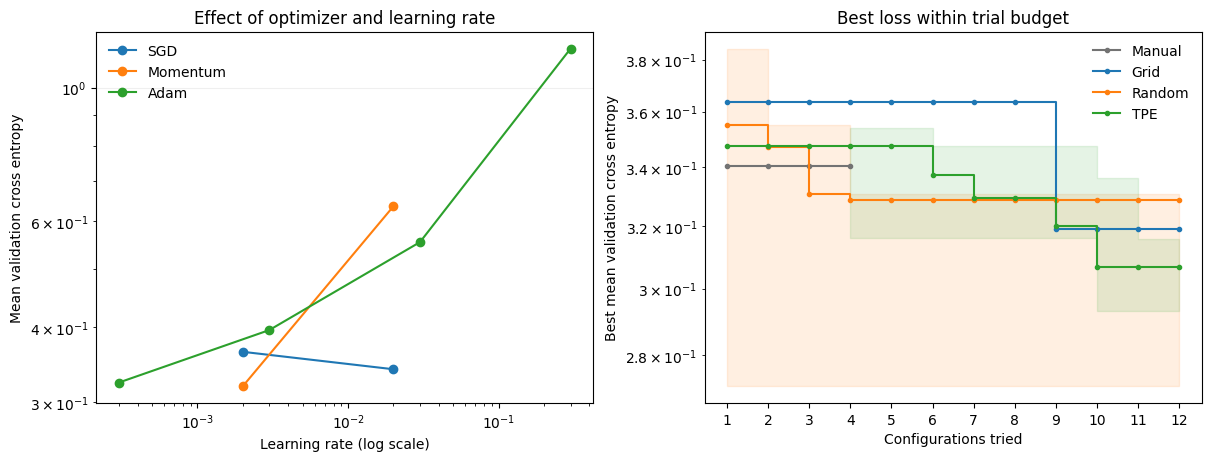

In [ ]:
search_labels = {
    "manual": ("Manual", "0.45"),
    "grid": ("Grid", "tab:blue"),
    "random": ("Random", "tab:orange"),
    "tpe": ("TPE", "tab:green"),
}

print("Method (seed)   Trials / Failed / Time     Best configuration      Fold loss / F1        Holdout loss / F1")
holdout_scores = {}
for method, repeats in search_runs.items():
    name, _ = search_labels[method]
    for seed, (rows, seconds) in zip(SEARCH_SEEDS, repeats):
        tag = f"{name} ({seed})" if len(repeats) > 1 else name
        failures = sum(row["failures"] > 0 for row in rows)
        summary = f"{tag:<12}{len(rows):>2} / {failures:<2} / {seconds:>5.1f} s"
        best = min(rows, key=lambda row: row["loss"])
        if not np.isfinite(best["loss"]):
            print(f"{summary}     All trials stopped")
            continue
        config = best["config"]
        if config not in holdout_scores:
            with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
                run = fit(my_lenet(config), train_data, val_data, TUNING_EPOCHS)
            holdout_scores[config] = run["history"][-1] if run["failure"] is None else None
        row = holdout_scores[config]
        holdout = f"{row['val_loss']:.4f} / {row['val_f1']:.4f}" if row is not None else "Stopped"
        print(f"{summary}     {config[0]:<9} {config[1]:.4g}     "
              f"{best['loss']:>7.4f} / {best['f1']:.4f}         {holdout}")

fig, (loss_ax, budget_ax) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
grid_rows = search_runs["grid"][0][0]
for kind in grid_rates:
    rows = sorted((row for row in grid_rows if row["config"][0] == kind),
                  key=lambda row: row["config"][1])
    losses = [row["loss"] if np.isfinite(row["loss"]) else np.nan for row in rows]
    loss_ax.loglog([row["config"][1] for row in rows], losses, "o-", label=kind)
loss_ax.set(title="Effect of optimizer and learning rate",
            xlabel="Learning rate (log scale)",
            ylabel="Mean validation cross entropy")

for method, repeats in search_runs.items():
    name, color = search_labels[method]
    curves = np.array([np.minimum.accumulate([row["loss"] for row in rows])
                       for rows, _ in repeats])
    trials = np.arange(1, curves.shape[1] + 1)
    median = np.median(curves, axis=0)
    budget_ax.step(trials, np.where(np.isfinite(median), median, np.nan),
                   where="post", marker="o", markersize=3, color=color, label=name)
    if len(curves) > 1:
        upper = curves.max(axis=0)
        budget_ax.fill_between(trials, curves.min(axis=0), upper, where=np.isfinite(upper),
                               step="post", color=color, alpha=0.12)
budget_ax.set(title="Best loss within trial budget",
              xlabel="Configurations tried",
              ylabel="Best mean validation cross entropy",
              yscale="log", xticks=range(1, budget + 1))
for ax in (loss_ax, budget_ax):
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.2)
plt.show()

## CUDA Benchmark

In a kernel with CUDA-enabled PyTorch and CuPy, set `RUN_CUDA_BENCHMARK = True`. Both implementations use the same GPU and FP32 inputs with matching training settings. Disable TF32 in PyTorch.

Warm up the forward and backward passes and the optimizer update. Start the measured run with the shared initial weights and fresh optimizer state. Place weights and inputs on the device before timing. Use device-wide synchronization in both frameworks. Gradient diagnostics and metric transfers are measured outside the training total.

For inference, warm up five times and report the median of 31 synchronized calls. These timings include dispatch and synchronization costs, which matter for small batches. The saved results use the same Anaconda Python environment for both CUDA backends.

NVIDIA GeForce RTX 5060 Laptop GPU | PyTorch 2.8.0+cu128 | CuPy 13.6.0 (CUDA runtime 12090)
CUDA agreement checked for initial logits, first loss, gradients, and parameter update.
MyDeZero CUDA  Accuracy=0.9667, Macro precision=0.9697, Macro recall=0.9667, Macro F1=0.9666
  Checkpoint epoch 28, convergence epoch 2, training 1.429 s, throughput 1,889 samples/s
  Median inference for batch sizes 1 / 15 (ms): 1.3546 / 1.3338
PyTorch CUDA  Accuracy=0.9667, Macro precision=0.9697, Macro recall=0.9667, Macro F1=0.9666
  Checkpoint epoch 19, convergence epoch 2, training 0.532 s, throughput 5,078 samples/s
  Median inference for batch sizes 1 / 15 (ms): 0.2755 / 0.2733


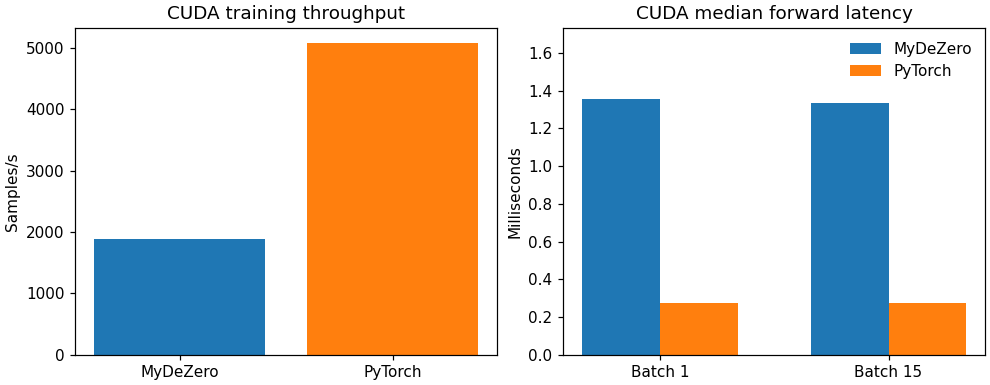

In [ ]:
RUN_CUDA_BENCHMARK = False


def show_cuda_comparison():
    if not torch.cuda.is_available() or not mydezero.cuda.gpu_enable:
        print("This cell requires CUDA-enabled PyTorch and CuPy in the current kernel.")
        return

    cp = mydezero.cuda.cupy
    try:
        if cp.cuda.runtime.getDeviceCount() == 0:
            print("CuPy did not detect a CUDA device.")
            return
    except cp.cuda.runtime.CUDARuntimeError as error:
        print(f"CuPy could not use the CUDA device: {error}")
        return

    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    print(f"{torch.cuda.get_device_name(0)} | PyTorch {torch.__version__} | "
          f"CuPy {cp.__version__} (CUDA runtime {cp.cuda.runtime.runtimeGetVersion()})")
    factories = {
        "MyDeZero": lambda: my_lenet(selected, xp=cp),
        "PyTorch": lambda: TorchTrial(selected, device="cuda:0"),
    }
    transfers = {
        "MyDeZero": cp.asarray,
        "PyTorch": lambda x: torch.as_tensor(x, device="cuda:0"),
    }

    summaries = {}
    with cp.cuda.Device(0), torch.cuda.device(0):
        device_splits = {
            name: [tuple(transfer(a) for a in split) for split in splits]
            for name, transfer in transfers.items()
        }
        warmups = [factory() for factory in factories.values()]
        assert all(isinstance(weight, cp.ndarray) for weight, _ in warmups[0].arrays())
        assert all(weight.is_cuda for weight, _ in warmups[1].arrays())
        first_batches = [tuple(a[:BATCH_SIZE] for a in data[0]) for data in device_splits.values()]
        verify_training_step(*warmups, *first_batches)
        print("CUDA agreement checked for initial logits, first loss, gradients, and parameter update.")
        for trial, batch in zip(warmups, first_batches):
            for _ in range(4):
                trial.backward(*batch)
                trial.update()
                trial.predict(batch[0])
            trial.synchronize()

        for name, factory in factories.items():
            train, validation, test = device_splits[name]
            trial = factory()
            run = fit(trial, train, validation, EPOCHS)
            assert run["failure"] is None
            _, scores = evaluate(trial, test)
            latency = [inference_ms(trial, test[0][:size]) for size in (1, BATCH_SIZE)]
            throughput = run["samples"] / run["seconds"]
            summaries[name] = (throughput, latency)
            print(f"{name} CUDA  " + ", ".join(f"{k}={v:.4f}" for k, v in zip(metric_names, scores)))
            print(f"  Checkpoint epoch {run['best']['row']['epoch']}, "
                  f"convergence epoch {convergence_epoch(run['history'])}, "
                  f"training {run['seconds']:.3f} s, throughput {throughput:,.0f} samples/s")
            print(f"  Median inference for batch sizes 1 / {BATCH_SIZE} (ms): "
                  + " / ".join(f"{value:.4f}" for value in latency))

    fig, (train_ax, inference_ax) = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    positions = np.arange(2)
    for i, (name, (throughput, latency)) in enumerate(summaries.items()):
        color = f"C{i}"
        train_ax.bar(i, throughput, color=color)
        inference_ax.bar(positions + (i - 0.5) * 0.34, latency, width=0.34, label=name, color=color)
    train_ax.set(xticks=positions, xticklabels=list(summaries), title="CUDA training throughput",
                 ylabel="Samples/s")
    inference_ax.set(xticks=positions, xticklabels=("Batch 1",
                                                f"Batch {BATCH_SIZE}"),
                     title="CUDA median forward latency",
                     ylabel="Milliseconds")
    inference_ax.set_ylim(0, 1.28 * max(max(times) for _, times in summaries.values()))
    inference_ax.legend(frameon=False, loc="upper right")
    plt.show()


if RUN_CUDA_BENCHMARK:
    show_cuda_comparison()
else:
    print("CUDA benchmark disabled. Enable it in a CUDA-capable kernel.")

## Exploratory Transfer Learning with Frozen ResNet50

Set `RUN_PRETRAINED_RESNET50 = True` to use a local DeZero-format weight archive. MyDeZero reads the archive directly. The default path is `models/dezero-official/resnet50.npz`. Edit `RESNET50_WEIGHTS` to use another compatible archive. [Official ResNet50 weights](https://github.com/koki0702/dezero-models/releases/download/v0.1/resnet50.npz)

Clip the synthetic grayscale input to a fixed range, map it to three channels, and subtract the channel means. Freeze the ImageNet ResNet50 backbone and extract 2,048-dimensional embeddings in inference mode. Standardize embeddings using training statistics. Train a linear head with Adam at a learning rate of 0.001 and select a checkpoint on the validation split. Report feature extraction and head training times separately.

An estimate of pretraining benefit would require an additional randomly initialized frozen ResNet50 with the same input and head.

Frozen ResNet50 feature extraction: 0.936 s. Head training: 0.035 s. Checkpoint epoch 28.
Accuracy         LeNet 0.9667  ResNet50 0.9333
Macro precision  LeNet 0.9697  ResNet50 0.9394
Macro recall     LeNet 0.9667  ResNet50 0.9333
Macro F1         LeNet 0.9666  ResNet50 0.9312


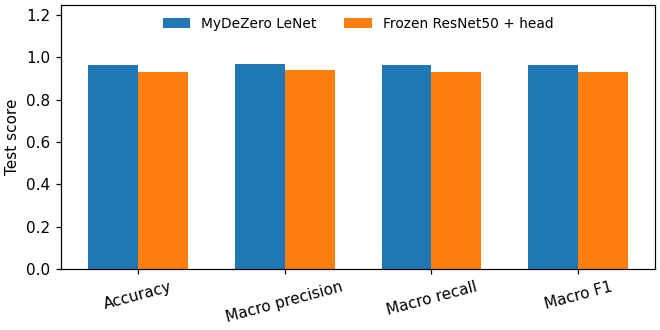

In [ ]:
RUN_PRETRAINED_RESNET50 = False
RESNET50_WEIGHTS = Path("models/dezero-official/resnet50.npz")


def run_frozen_resnet():
    try:
        from mydezero.models import ResNet50
    except ImportError as error:
        raise ImportError("This cell requires a MyDeZero installation with ResNet50.") from error

    class Identity(mydezero.Layer):
        def forward(self, x):
            return x

    class IrisHead(mydezero.Model):
        def __init__(self):
            super().__init__()
            self.head = L.Linear(N_CLASSES, in_size=2048)

        def forward(self, x):
            return self.head(x)

    weights = RESNET50_WEIGHTS.expanduser()
    if not weights.is_absolute():
        weights = next((root / weights for root in (Path.cwd(), *Path.cwd().parents)
                        if (root / weights).is_file()), weights)
    if not weights.is_file():
        raise FileNotFoundError(weights)

    backbone = ResNet50()
    backbone.load_weights(weights)
    backbone.fc6 = Identity()

    def featurize(split):
        x, labels = split
        pixels = (np.clip(x, -3.0, 3.0) + 3.0) * np.float32(255 / 6)
        bgr = pixels - np.array([103.939, 116.779, 123.68], dtype=np.float32)[None, :, None, None]
        with mydezero.test_mode(), mydezero.no_grad():
            embedding = np.concatenate([backbone(bgr[i:i + BATCH_SIZE]).data
                                        for i in range(0, len(labels), BATCH_SIZE)])
        assert embedding.shape == (len(labels), 2048)
        return embedding, labels

    started = perf_counter()
    train, validation, test = [featurize(split) for split in splits]
    extraction_seconds = perf_counter() - started
    scale = np.maximum(train[0].std(axis=0), np.float32(1e-3))
    center = train[0].mean(axis=0)
    train, validation, test = [((x - center) / scale, y) for x, y in (train, validation, test)]
    init = {"head": (np.zeros((2048, N_CLASSES), dtype=np.float32),
                     np.zeros(N_CLASSES, dtype=np.float32))}
    head = MyDeZeroTrial(IrisHead(), ("head",), init, ("Adam", 0.001))
    result = fit(head, train, validation, EPOCHS)
    assert result["failure"] is None and result["best"] is not None
    _, scores = evaluate(result["trial"], test)
    print(f"Frozen ResNet50 feature extraction: {extraction_seconds:.3f} s. "
          f"Head training: {result['seconds']:.3f} s. Checkpoint epoch {result['best']['row']['epoch']}.")
    for metric, lenet, resnet in zip(metric_names, test_scores["MyDeZero"], scores):
        print(f"{metric:<16} LeNet {lenet:.4f}  ResNet50 {resnet:.4f}")
    positions = np.arange(len(metric_names))
    fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
    ax.bar(positions - 0.17, test_scores["MyDeZero"], 0.34, label="MyDeZero LeNet")
    ax.bar(positions + 0.17, scores, 0.34, label="Frozen ResNet50 + head")
    ax.set(xticks=positions, xticklabels=metric_names, ylim=(0, 1.25), ylabel="Test score")
    ax.tick_params(axis="x", labelrotation=15)
    ax.legend(loc="upper center", ncol=2, fontsize=9, frameon=False)
    plt.show()


if RUN_PRETRAINED_RESNET50:
    run_frozen_resnet()
else:
    print("Frozen ResNet50 comparison disabled.")

## Findings and Scope

- **Task baseline.** Logistic regression answers 30 of 30 correctly on the four original features. The one-sample margin over LeNet makes this a useful reference for the difficulty of this split.
- **Framework agreement.** The CPU LeNet models agree on all 30 predictions. Both misclassify the same virginica as versicolor. The CUDA runs also match on test accuracy and macro F1.
- **Search.** Four of 12 grid candidates stop with non-finite values. The manual, grid, and random-search selections all achieve a holdout macro F1 of 1.0000. Holdout cross-entropy is 0.1046 for the manual selection, 0.0854 for the grid, and 0.0251–0.0656 across three random-search seeds. TPE spans 0.0836–0.1164 on holdout. Compare both fold and holdout results when interpreting the rankings.
- **Training diagnostics.** With the selected learning rate, training and validation performance track one another over the observed run. At a learning rate of 1.0, the peak weight-gradient norm rises from about 17 to 4.5 million, and validation accuracy falls to about 33%.
- **Performance.** The CPU and CUDA sections report per-framework measurements. Batch size changes the balance between computation, dispatch, and synchronization. These measurements apply to this model and environment.
- **Transfer learning.** The frozen ResNet50 with a linear head answers 28 of 30 correctly on the synthetic inputs. The result describes this classification pipeline and split.

Each test prediction accounts for 3.33 percentage points of accuracy. Repeated stratified splits would help assess variation in model scores. Alternating the frameworks over repeated measurements would quantify timing variability.